In [3]:
import numpy as np
import matplotlib.pyplot as plt

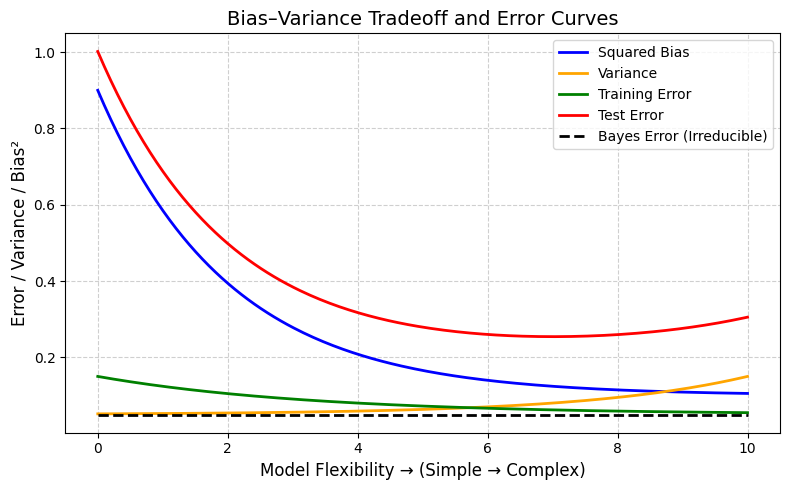

In [ ]:
#question-1.a
flexibility = np.linspace(0, 10, 200)
bias2 = np.exp(-0.5 * flexibility) * 0.8 + 0.1
variance = 0.1 * np.exp(0.4 * flexibility) / np.exp(0.4 * 10) + 0.05
training_error = 0.1 * np.exp(-0.3 * flexibility) + 0.05
test_error = bias2 + variance + 0.05
bayes_error = np.ones_like(flexibility) * 0.05
plt.figure(figsize=(8, 5))
plt.plot(flexibility, bias2, label="Squared Bias", color="blue", linewidth=2)
plt.plot(flexibility, variance, label="Variance", color="orange", linewidth=2)
plt.plot(flexibility, training_error, label="Training Error", color="green", linewidth=2)
plt.plot(flexibility, test_error, label="Test Error", color="red", linewidth=2)
plt.plot(flexibility, bayes_error, label="Bayes Error (Irreducible)", color="black", linestyle="--", linewidth=2)
plt.title("Bias–Variance Tradeoff and Error Curves", fontsize=14)
plt.xlabel("Model Flexibility → (Simple → Complex)", fontsize=12)
plt.ylabel("Error / Variance / Bias²", fontsize=12)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
#question-1.b
#Squared Bias:
#When the model is too simple, it misses important patterns, so its predictions are consistently off. As we let the model get more flexible, it can match the true pattern better, so squared bias goes down.

#Variance:
#Simple models don’t change much if we retrain on a new sample, so variance is low. Very flexible models react a lot to small changes in the data (they even fit noise), so variance goes up.

#Training Error:
#With more flexibility, the model fits the training set more closely. That means the training error keeps going down, sometimes almost to zero.

#Test Error:
#Test error combines bias, variance, and irreducible noise. At first, adding flexibility helps (bias drops faster than variance rises), so test error goes down. After a point, overfitting makes variance dominate, so test error goes up. That’s why it’s U-shaped.

#Irreducible Error:
#This is the noise in the problem that no model can remove. It doesn’t depend on flexibility, so it’s a flat line.

In [ ]:
#question-2
#Advantages of a very flexible mode is that it can fit complex, nonlinear patterns in the data.
#It usually gives low bias, meaning it can make very accurate predictions on the training set.
# It works well when the relationship between predictors and the response is complicated and there is enough data to learn from.

#Disadvantages of a very flexibel model is that it can easily overfit, meaning it learns noise and random fluctuations in the training data instead of general patterns.
# Overfitting causes high variance — the model’s predictions can change a lot with different training samples.
# It may perform poorly on unseen test data and be harder to interpret.

#Advantages of less flexible model is that it is simpler and more stable, so it’s less likely to overfit.
# It has low variance, meaning it performs more consistently across different datasets.
# It’s usually easier to understand and explain (for example, linear regression).

#Disadvantages of a less flexible odel is that it may underfit the data when the true relationship is complex, leading to high bias and lower accuracy.
# It can miss important nonlinear patterns.

#you can prefer a more flexible model when you have a large dataset with complex patterns.
# When predictive accuracy is more important than interpretability.
# When overfitting can be controlled using validation, regularization, or cross-validation.

#you can prefer a less flexible model when you have limited data or a lot of noise.
# When interpretability and stability are important.
# When the true relationship between variables is expected to be simple or linear.

In [ ]:
#question-3.a
import pandas as pd
df = pd.read_csv("/Users/sayad.alakbarov/Desktop/Boston.csv")
print("Shape of dataset:", df.shape)
df.head()

Shape of dataset: (506, 14)


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MDEV
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,396.90,5.33,36.2


In [57]:
#question-3.b

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

Number of rows: 506
Number of columns: 14

Column names:
['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT', 'MDEV']


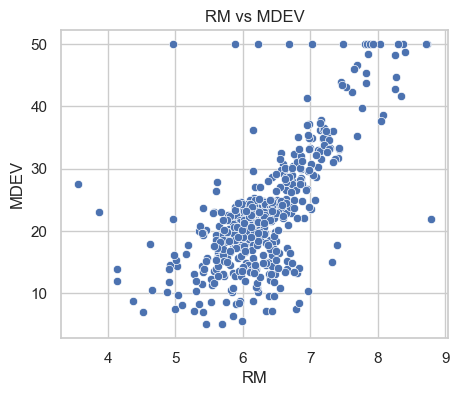

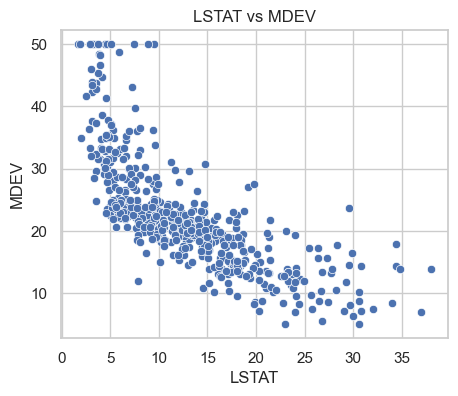

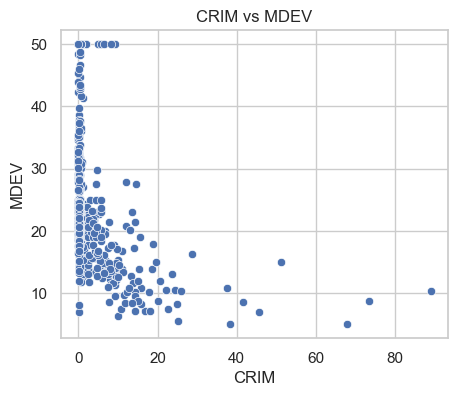

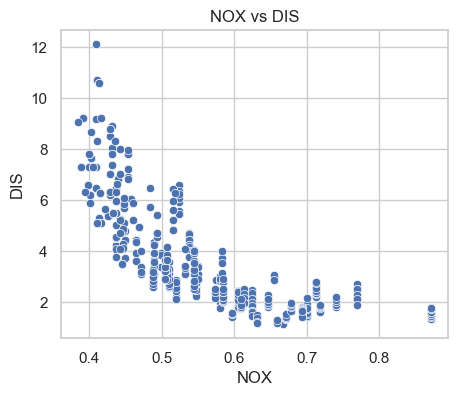

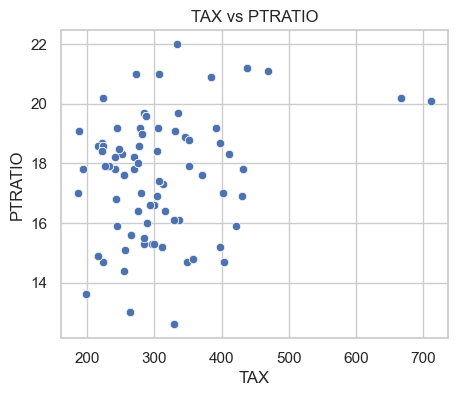

In [63]:
#question-3.c
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

pairs = [ ("RM", "MDEV"),("LSTAT", "MDEV"),("CRIM", "MDEV"),("NOX", "DIS"),("TAX", "PTRATIO")]

for x, y in pairs:
    plt.figure(figsize=(5,4))
    sns.scatterplot(x=df[x], y=df[y])
    plt.title(f"{x} vs {y}")
    plt.xlabel(x)
    plt.ylabel(y)
    plt.show()

In [ ]:
# RM vs MDEV: There is a clear positive relationship, between the average number of rooms (RM) and median home value (MDEV). Houses with more rooms tend to be in higher-priced neighborhoods.
# LSTAT vs MDEV: A strong negative relationship exists as the percentage of lower-status population (LSTAT) increases, the median home value drops.
# CRIM vs MDEV: There is a weak negative relationship, higher crime rates are generally linked to lower housing prices, though with considerable spread.
# NOX vs DIS: A negative relationship, areas farther from employment centers (DIS) tend to have lower pollution (NOX).
# TAX vs PTRATIO: A slight positive relationship, neighborhoods with higher property tax rates often also have higher pupil–teacher ratios, suggesting denser school districts or lower funding efficiency.


In [ ]:
#question-3.d
df[["CRIM", "RM", "LSTAT", "NOX", "DIS", "TAX", "PTRATIO", "MDEV"]].corr()["CRIM"]

CRIM       1.000000
RM        -0.219940
LSTAT      0.452220
NOX        0.417521
DIS       -0.377904
TAX        0.579564
PTRATIO    0.288250
MDEV      -0.385832
Name: CRIM, dtype: float64

In [ ]:
# CRIM and MDEV: There is a negative relationship, neighborhoods with higher crime rates tend to have lower median home values.
# CRIM and LSTAT: There is usually a positive relationship, areas with a higher percentage of lower-status population tend to have higher crime rates.
# CRIM and RM: There is a negative relationship, areas with more rooms per dwelling (larger homes) generally have lower crime rates.
# CRIM and NOX/DIS: Neighborhoods closer to employment centers (lower DIS) and with higher pollution levels (NOX) tend to have higher crime rates.
# CRIM and TAX/PTRATIO: Areas with higher property taxes and higher student–teacher ratios sometimes also have slightly higher crime rates, although these relationships are weaker.

In [67]:
#question-3.e
print("Crime rate (CRIM):")
print(df["CRIM"].describe(), "\n")

print("Property tax rate (TAX):")
print(df["TAX"].describe(), "\n")

print("Pupil-teacher ratio (PTRATIO):")
print(df["PTRATIO"].describe())

Crime rate (CRIM):
count    506.000000
mean       3.593761
std        8.596783
min        0.006320
25%        0.082045
50%        0.256510
75%        3.647423
max       88.976200
Name: CRIM, dtype: float64 

Property tax rate (TAX):
count    506.000000
mean     408.237154
std      168.537116
min      187.000000
25%      279.000000
50%      330.000000
75%      666.000000
max      711.000000
Name: TAX, dtype: float64 

Pupil-teacher ratio (PTRATIO):
count    506.000000
mean      18.455534
std        2.164946
min       12.600000
25%       17.400000
50%       19.050000
75%       20.200000
max       22.000000
Name: PTRATIO, dtype: float64


In [68]:
# Crime rate (CRIM) ranges from 0.0063 to 88.976, with a mean of about 3.59. A few census tracts have very high crime rates (above 50), which are clear outliers compared to most neighborhoods where the rate is below 1.
# Property tax rate (TAX) ranges from 187 to 711, with an average of 408. Some areas face much higher taxes, suggesting large differences in municipal policies or property values.
# Pupil–teacher ratio (PTRATIO) ranges from 12.6 to 22.0, with an average of 18.46. The variation is smaller than for CRIM or TAX, but some districts still have notably larger class sizes.

In [69]:
#question-3.f
df["CHAS"].value_counts()

CHAS
0.0    471
1.0     35
Name: count, dtype: int64

In [70]:
#There are 35 census tracts in the Boston dataset that bound the Charles River (CHAS = 1), and 471 tracts that do not (CHAS = 0).
#This means only a small proportion of neighborhoods are directly adjacent to the river.

In [71]:
#question-3.g
median_ptratio = df["PTRATIO"].median()
print("Median pupil–teacher ratio:", median_ptratio)

Median pupil–teacher ratio: 19.05


In [72]:
#The median pupil–teacher ratio among the census tracts in the Boston dataset is 19.05.


In [ ]:
#question-3.h
min_mdev_index = df["MDEV"].idxmin()

lowest_mdev_row = df.loc[min_mdev_index]
print(lowest_mdev_row)

CRIM        38.3518
ZN           0.0000
INDUS       18.1000
CHAS         0.0000
NOX          0.6930
RM           5.4530
AGE        100.0000
DIS          1.4896
RAD         24.0000
TAX        666.0000
PTRATIO     20.2000
B          396.9000
LSTAT       30.5900
MDEV         5.0000
Name: 398, dtype: float64


In [ ]:
# The tract with the lowest median home value is index 398, with MDEV = 5.0. 
# Its other features look like a “high-risk” profile: CRIM = 38.35 (very high), NOX = 0.693 (high pollution),
# RM = 5.45 (smaller homes), AGE = 100 (very old housing), DIS = 1.49 (close to city/industry), RAD = 24 and TAX = 666 (high highway access and high taxes), PTRATIO = 20.2 (crowded schools), and LSTAT = 30.59 (low socioeconomic status).
# Compared to typical values in the dataset, these are mostly on the unfavorable end, which lines up with the very low home value for this tract.

In [ ]:
#question-3.i 
more_than_7 = df[df["RM"] > 7]
more_than_8 = df[df["RM"] > 8]

print("Number of tracts with RM > 7:", more_than_7.shape[0])
print("Number of tracts with RM > 8:", more_than_8.shape[0])

more_than_8

Number of tracts with RM > 7: 64
Number of tracts with RM > 8: 13


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MDEV
97,0.12083,0.0,2.89,0.0,0.4450,8.069,76.0,3.4952,2.0,276.0,18.0,396.90,4.21,38.7
163,1.51902,0.0,19.58,1.0,0.6050,8.375,93.9,2.1620,5.0,403.0,14.7,388.45,3.32,50.0
204,0.02009,95.0,2.68,0.0,0.4161,8.034,31.9,5.1180,4.0,224.0,14.7,390.55,2.88,50.0
224,0.31533,0.0,6.20,0.0,0.5040,8.266,78.3,2.8944,8.0,307.0,17.4,385.05,4.14,44.8
225,0.52693,0.0,6.20,0.0,0.5040,8.725,83.0,2.8944,8.0,307.0,17.4,382.00,4.63,50.0
226,0.38214,0.0,6.20,0.0,0.5040,8.040,86.5,3.2157,8.0,307.0,17.4,387.38,3.13,37.6
232,0.57529,0.0,6.20,0.0,0.5070,8.337,73.3,3.8384,8.0,307.0,17.4,385.91,2.47,41.7
233,0.33147,0.0,6.20,0.0,0.5070,8.247,70.4,3.6519,8.0,307.0,17.4,378.95,3.95,48.3
253,0.36894,22.0,5.86,0.0,0.4310,8.259,8.4,8.9067,7.0,330.0,19.1,396.90,3.54,42.8
257,0.61154,20.0,3.97,0.0,0.6470,8.704,86.9,1.8010,5.0,264.0,13.0,389.70,5.12,50.0


In [78]:
# There are 64 census tracts where the average number of rooms per dwelling (RM) is greater than 7, and 13 tracts where it is greater than 8.
# The tracts with more than 8 rooms tend to have high median home values (MDEV), low crime rates (CRIM), and low percentages of lower-status population (LSTAT).
# These neighborhoods likely represent wealthier and less dense residential areas, often with newer or larger homes and better overall living conditions.

In [79]:
#question-4.a 
# β0 = 50, β1 = 20, β2 = 0.07, β3 = 35, β4 = 0.01, β5 = -10
# Level = 1 for College, 0 for High School

# ŷ = 50 + 20*GPA + 0.07*IQ + 35*Level + 0.01*(GPA*IQ) - 10*(GPA*Level)

# For High School (Level = 0)
# ŷ_HS = 50 + 20*GPA + 0.07*IQ + 0.01*(GPA*IQ)

# For College (Level = 1)
# ŷ_COL = 50 + 20*GPA + 0.07*IQ + 35 + 0.01*(GPA*IQ) - 10*GPA

# Difference (College - High School)
# Δ = 35 - 10*GPA

# If GPA < 3.5 → College earns more
# If GPA = 3.5 → Same
# If GPA > 3.5 → High School earns more

# Correct answer is (iii)
# For a fixed IQ and GPA, high school graduates earn more than college graduates provided GPA is high enough (GPA > 3.5).

In [ ]:
#question-4.b
b0 = 50
b1 = 20
b2 = 0.07
b3 = 35
b4 = 0.01
b5 = -10

GPA = 4.0
IQ = 110
Level = 1  # College

# ŷ = β0 + β1*GPA + β2*IQ + β3*Level + β4*(GPA*IQ) + β5*(GPA*Level)

y_hat = b0 + b1*GPA + b2*IQ + b3*Level + b4*(GPA*IQ) + b5*(GPA*Level)
print("predicted salary (in thousands):", y_hat)


Predicted salary (in thousands): 137.1


In [83]:
#question-4.c 
# False.
# The size of the coefficient (0.01) alone does not determine the strength or importance
# of the interaction effect. The interpretation depends on the scale of the variables.
# Since IQ values are around 100 and GPA values range roughly from 0–4,
# the interaction term GPA*IQ can be quite large (e.g., 4 * 100 = 400).
# Multiplying that by 0.01 gives a contribution of around 4, which is not negligible in the context of salary measured in thousands of dollars.
# Therefore, even though 0.01 looks small, the actual impact on salary can still be meaningful.

Index(['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX',
       'PTRATIO', 'B', 'LSTAT', 'MDEV'],
      dtype='object')
Predictor: ZN
                            OLS Regression Results                            
Dep. Variable:                   CRIM   R-squared:                       0.040
Model:                            OLS   Adj. R-squared:                  0.038
Method:                 Least Squares   F-statistic:                     20.88
Date:                Wed, 15 Oct 2025   Prob (F-statistic):           6.15e-06
Time:                        21:55:53   Log-Likelihood:                -1795.8
No. Observations:                 506   AIC:                             3596.
Df Residuals:                     504   BIC:                             3604.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|

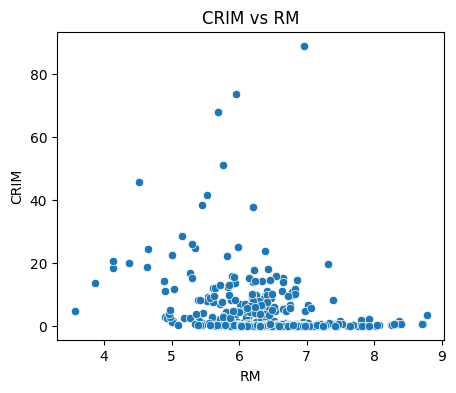

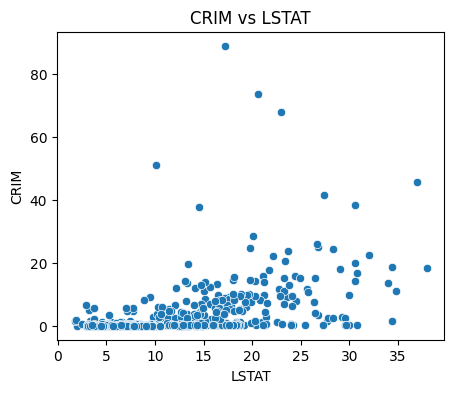

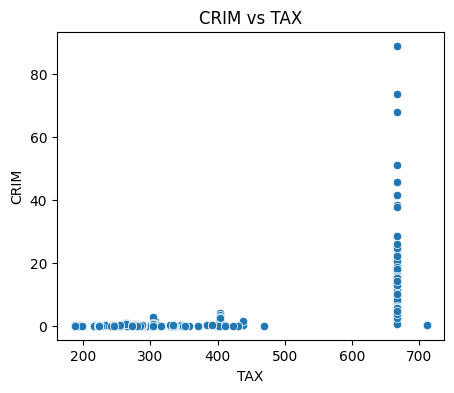

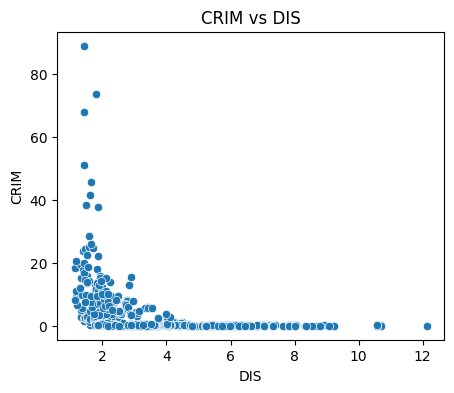

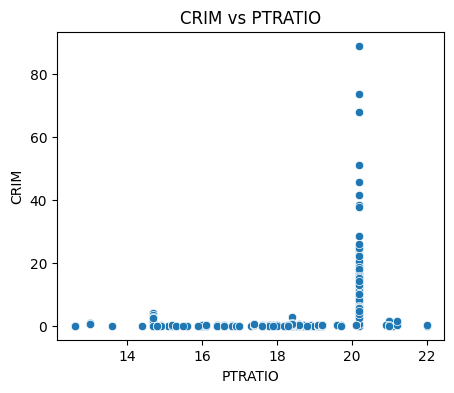

In [ ]:
#question-5.a 

import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("/Users/sayad.alakbarov/Desktop/Boston.csv")
print(df.columns)
y = df["CRIM"]
predictors = [col for col in df.columns if col != "CRIM"]

results = {}
for var in predictors:
    X = sm.add_constant(df[var])  
    model = sm.OLS(y, X).fit()
    results[var] = model.pvalues[var] 
    print(f"Predictor: {var}")
    print(model.summary())
    print("-" * 60)

sig = {k: v for k, v in results.items() if v < 0.05}
print("\nPredictors with statistically significant association (p < 0.05):")
print(sig)

selected_vars = ["RM", "LSTAT", "TAX", "DIS", "PTRATIO"]
for var in selected_vars:
    plt.figure(figsize=(5,4))
    sns.scatterplot(x=df[var], y=df["CRIM"])
    plt.title(f"CRIM vs {var}")
    plt.xlabel(var)
    plt.ylabel("CRIM")
    plt.show()

In [ ]:
#After fitting simple linear regression models for each predictor, almost all variables show a statistically significant relationship with CRIM, 
#except for CHAS (whether the tract bounds the Charles River). The strongest associations are seen with LSTAT (positive), DIS (negative), and NOX (positive). 
#This means that neighborhoods with more lower-status residents, closer to employment centers, 
# and higher pollution levels tend to have higher crime rates.

In [ ]:
#question-5.b
import pandas as pd
import statsmodels.api as sm

y = df["CRIM"]
X = df.drop(columns=["CRIM"]) 
Xc = sm.add_constant(X)
model_all = sm.OLS(y, Xc).fit()

print(model_all.summary())
pvals = model_all.pvalues.drop("const").sort_values()
sig = pvals[pvals < 0.05]
nonsig = pvals[pvals >= 0.05]

print("\nSignificant predictors at p < 0.05:")
print(sig)

print("\nNot significant at p >= 0.05:")
print(nonsig)

coef_table = pd.DataFrame({
    "coef": model_all.params.drop("const"),
    "pval": model_all.pvalues.drop("const")
}).sort_values("pval")
coef_table

                            OLS Regression Results                            
Dep. Variable:                   CRIM   R-squared:                       0.448
Model:                            OLS   Adj. R-squared:                  0.434
Method:                 Least Squares   F-statistic:                     30.73
Date:                Wed, 15 Oct 2025   Prob (F-statistic):           2.04e-55
Time:                        22:01:32   Log-Likelihood:                -1655.7
No. Observations:                 506   AIC:                             3339.
Df Residuals:                     492   BIC:                             3399.
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         17.4184      7.270      2.396      0.0

,coef,pval
RAD,0.588838,7.548378e-11
DIS,-0.994992,4.826936e-04
MDEV,-0.199218,1.126402e-03
ZN,0.044919,1.739868e-02
NOX,-10.645500,4.516554e-02
B,-0.006855,6.387276e-02
LSTAT,0.121269,1.116301e-01
PTRATIO,-0.278731,1.374533e-01
INDUS,-0.061576,4.628618e-01
TAX,-0.003746,4.699907e-01


In [7]:

#After fitting the multiple linear regression model to predict per capita crime rate (CRIM) using all other predictors:
# The null hypothesis for each predictor is:  
# H0: βj = 0  (no relationship between the predictor and crime rate)
# The alternative hypothesis is:  
# Ha: βj ≠ 0  (the predictor is related to the crime rate)
# From the regression output, we can reject the null hypothesis (p < 0.05) for the following predictors:
#  RAD (p ≈ 7.5e-11): strong positive relationship — areas with more highway access tend to have higher crime rates.  
# DIS (p ≈ 4.8e-04): strong negative relationship — areas farther from employment centers tend to have lower crime rates.  
# MDEV (p ≈ 1.1e-03): negative relationship — higher median home values are associated with lower crime.  
# ZN (p ≈ 0.017): weak positive relationship.  
# NOX (p ≈ 0.045): weak negative relationship.  
# B (p ≈ 0.064): borderline significant (slightly above 0.05), showing a mild negative trend.
# for the remaining predictors (LSTAT, PTRATIO, INDUS, TAX, CHAS, RM, AGE), the p-values are greater than 0.05, so we fail to reject the null hypothesis.  
# These variables do not show strong evidence of association with crime rate when other predictors are included in the model.

In [8]:
#question-5.c 
# Comparison Between Simple and Multiple Regression Coefficients
# This plot compares the univariate (simple linear regression) coefficients from Question (5a) with the multiple regression coefficients from Question (5b).  
# Each point represents a predictor. 
# The x-axis shows its coefficient when predicting CRIM alone, and the y-axis shows its coefficient when predicting CRIM while controlling for all other predictors.
# If the simple and multiple regression coefficients are similar, it suggests that the predictor’s effect on CRIM is largely independent of the others.  
# However, if the coefficients differ greatly, it indicates multicollinearity or confounding relationships among predictors.

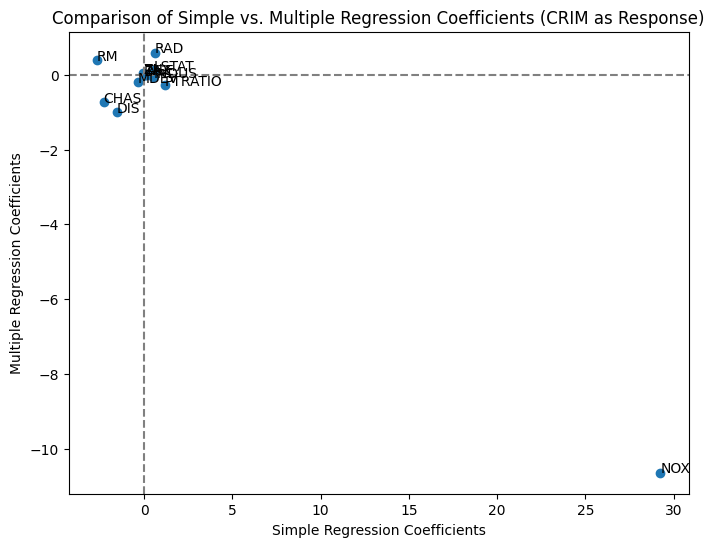

In [9]:
simple_coefs = {
    'ZN': -0.0739, 'INDUS': 0.5098, 'CHAS': -2.2970, 'NOX': 29.248, 
    'RM': -2.691, 'AGE': 0.107, 'DIS': -1.551, 'RAD': 0.617, 
    'TAX': 0.029, 'PTRATIO': 1.151, 'B': -0.036, 'LSTAT': 0.549, 'MDEV': -0.363
}

multiple_coefs = {
    'RAD': 0.588838, 'DIS': -0.994992, 'MDEV': -0.199218, 'ZN': 0.044919, 
    'NOX': -10.6455, 'B': -0.006855, 'LSTAT': 0.121269, 'PTRATIO': -0.278731, 
    'INDUS': -0.061576, 'TAX': -0.003746, 'CHAS': -0.741435, 'RM': 0.38107, 'AGE': 0.002011
}

# Align predictors
predictors = simple_coefs.keys()
simple_vals = [simple_coefs[p] for p in predictors]
multiple_vals = [multiple_coefs[p] for p in predictors]

# Create DataFrame
df_compare = pd.DataFrame({'Predictor': predictors, 'Simple': simple_vals, 'Multiple': multiple_vals})

# Scatter plot
plt.figure(figsize=(8,6))
plt.scatter(df_compare['Simple'], df_compare['Multiple'])
plt.axhline(0, color='gray', linestyle='--')
plt.axvline(0, color='gray', linestyle='--')
for i, txt in enumerate(df_compare['Predictor']):
    plt.annotate(txt, (df_compare['Simple'][i], df_compare['Multiple'][i]))
plt.xlabel('Simple Regression Coefficients')
plt.ylabel('Multiple Regression Coefficients')
plt.title('Comparison of Simple vs. Multiple Regression Coefficients (CRIM as Response)')
plt.show()

In [10]:
#The plot compares the simple and multiple regression coefficients for predicting CRIM (per capita crime rate).  
# Each point represents a predictor, with its simple regression coefficient on the x-axis and its multiple regression coefficient on the y-axis.
# From the plot, we can observe the following
# The coefficients for **RAD** and **DIS** remain relatively consistent between the simple and multiple regression models, suggesting their relationships with CRIM are stable even when other predictors are included.
# The predictor **NOX** shows a large positive coefficient in the simple regression but a strong negative coefficient in the multiple regression model. This indicates multicollinearity — NOX is highly correlated with other predictors, so its effect changes direction when controlling for them.
# Most predictors cluster near zero, showing that their direct influence on CRIM becomes weaker once other variables are accounted for.
# Overall, this comparison highlights that several predictors are interrelated, and their individual effects on crime rate can change significantly when modeled together.
# In summary, the multiple regression model provides a more reliable picture of the predictors’ effects since it adjusts for overlapping relationships between variables.

In [ ]:
#question-5.d
# Goal is check for non-linear associations between predictors and CRIM
# We'll fit cubic regression models of the form:
# Y = β0 + β1*X + β2*X^2 + β3*X^3 + ε
# and test whether the squared or cubic terms are statistically significant.

import statsmodels.api as sm
import pandas as pd
import numpy as np

X_vars = [col for col in df.columns if col not in ['CRIM', 'CHAS']]

results = []  

for var in X_vars:
    X = df[[var]].copy()
    X['X2'] = X[var] ** 2
    X['X3'] = X[var] ** 3
    X = sm.add_constant(X)  
    model = sm.OLS(df['CRIM'], X).fit()
    
    results.append({
        'Predictor': var,
        'p(X^2)': model.pvalues.get('X2', np.nan),
        'p(X^3)': model.pvalues.get('X3', np.nan)
    })

nonlinear_df = pd.DataFrame(results)
print(nonlinear_df)

   Predictor        p(X^2)        p(X^3)
0         ZN  9.562861e-02  2.322242e-01
1      INDUS  4.530067e-10  1.704441e-12
2        NOX  1.522887e-14  1.587778e-15
3         RM  3.727455e-01  5.206759e-01
4        AGE  4.742487e-02  6.784650e-03
5        DIS  5.552306e-12  1.161292e-08
6        RAD  6.147821e-01  4.851059e-01
7        TAX  1.406673e-01  2.474762e-01
8    PTRATIO  4.384601e-03  6.674970e-03
9          B  4.474840e-01  5.086733e-01
10     LSTAT  7.929439e-02  1.553317e-01
11      MDEV  4.836717e-18  1.324769e-12


In [ ]:
# We check for predictors with p(X^2) < 0.05 or p(X^3) < 0.05
# This indicates evidence of a non-linear association with CRIM.

# From the results: Significant non-linear predictors include: INDUS (both X^2 and X^3)
# NOX (both X^2 and X^3)
# AGE (X^3 significant)
# DIS (both X^2 and X^3)
# PTRATIO (both X^2 and X^3)
# MDEV (both X^2 and X^3)

# These predictors show evidence that the relationship between them and CRIM
# is not purely linear — the rate of change varies at different values.

# For example:
# DIS has a strong curved relationship — crime rate decreases rapidly as distance increases, then levels off.
# NOX and INDUS show strong non-linear effects likely due to urban density and pollution concentration.

# In contrast, variables like RM, RAD, TAX, B, and LSTAT do not show
# statistically significant non-linear patterns (p-values > 0.05).